# 内容自适应软融合 P2P — PIE-Bench 实验

比较 `p2p`、`soft_fixed`、`soft_adaptive`；不训练模型，不采用逐层或逐头权重。
共享 DDIM 反演，使用固定版本 PnP Inversion 指标。支持网页 Colab 和 VS Code Colab 扩展，T4或A100。
每次处理一对提示词；本版只运行真实 PIE 图像。历史实验保留，升级协议请使用新的实验名称。

## 1. 项目与持久化目录

在 VS Code 本地资源管理器右键随附的 `adaptive_p2p_colab_bundle.zip` → **Upload to Colab**。
在 Colab 侧栏 **Contents** 查看实际远端路径；默认检查 `/content/adaptive_p2p_colab_bundle.zip`。
若上传路径不同，设置 `BUNDLE_PATH_OVERRIDE`；若已上传/克隆完整源码，设置 `PROJECT_DIR_OVERRIDE`。

推荐先执行命令 **Colab: Mount Google Drive to Server...** 并运行扩展插入的挂载单元格。
本程序不自行执行网页挂载。已挂载时默认保存到 Drive，否则使用 `/content/p2p_results`（临时）。
重启 kernel 后重跑本节。只有放在临时 `/content` 的文件才需在更换服务器后恢复。
可把代码 ZIP 一次上传到 Drive，然后设置
`BUNDLE_PATH_OVERRIDE="/content/drive/MyDrive/adaptive_p2p_colab_bundle.zip"`；
每台新服务器会从 Drive 自动解压到同一个 `/content/adaptive_p2p`，无需再次从电脑上传。
数据放在 Drive，结果直接写入 Drive 时，重新挂载并保持原路径即可，无需解压结果包。
新服务器仍需重新安装依赖；默认模型缓存位于临时磁盘，需重新下载。

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os, sys
from pathlib import Path
PROJECT_DIR_OVERRIDE = None
BUNDLE_PATH_OVERRIDE = None
RESULTS_ROOT_OVERRIDE = "/content/drive/MyDrive/p2p_research"
REMOTE_ROOT = "/content" if sys.platform == "linux" and Path("/content").is_dir() else None
IN_COLAB = REMOTE_ROOT is not None
"""Standard-library bootstrap, embedded in the notebook before project imports.

Works with VS Code Colab extension, browser Colab and a local gvproj kernel.
No frontend-specific upload, download or authentication widgets are invoked.
"""
import hashlib
import os
import sys
import zipfile
from pathlib import Path, PureWindowsPath


def runtime_path(value, *, base=None):
    value = str(value)
    if os.name != "nt" and (PureWindowsPath(value).drive or "\\" in value):
        raise ValueError("Remote Linux cannot read a Windows path. Upload the file and use its /content/... path: " + value)
    path = Path(value).expanduser()
    return ((Path(base) / path) if base is not None and not path.is_absolute() else path).resolve()


def extract_runtime_bundle(bundle, destination):
    bundle, destination = Path(bundle), Path(destination).resolve()
    checksum = hashlib.sha256(bundle.read_bytes()).hexdigest()
    marker = destination / ".uploaded_bundle_sha256"
    if marker.exists() and marker.read_text().strip() == checksum:
        return destination
    if any(name in sys.modules for name in ("adaptive_p2p", "evaluate_adaptive_p2p")):
        raise RuntimeError("New project bundle detected. Restart Kernel before extracting updated code.")
    with zipfile.ZipFile(bundle) as archive:
        # Check the complete archive before extracting anything.
        for member in archive.infolist():
            name = member.filename
            path = destination / name
            if PureWindowsPath(name).drive or "\\" in name or not path.resolve().is_relative_to(destination):
                raise ValueError("Unsafe archive member: " + name)
            if (member.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError("Archive symlinks are not supported: " + name)
        if "adaptive_p2p.py" not in archive.namelist():
            raise ValueError("Use the generated flat adaptive_p2p_colab_bundle.zip.")
        destination.mkdir(parents=True, exist_ok=True)
        archive.extractall(destination)
    marker.write_text(checksum, encoding="utf-8")
    return destination


def setup_runtime(project_dir=None, bundle_path=None, remote_root=None, results_root=None):
    cwd = Path.cwd()
    remote = runtime_path(remote_root) if remote_root else None
    if project_dir:
        project = runtime_path(project_dir, base=remote or cwd)
    elif remote:
        project = remote / "adaptive_p2p"
    else:
        candidates = [p for p in (cwd, *cwd.parents) if (p / "adaptive_p2p.py").is_file()]
        if not candidates:
            raise FileNotFoundError("Set PROJECT_DIR_OVERRIDE to the project directory visible to this kernel.")
        project = candidates[0]
    bundle = runtime_path(bundle_path, base=remote or cwd) if bundle_path else (
        remote / "adaptive_p2p_colab_bundle.zip" if remote else None)
    # Explicit project override uses uploaded source files; explicit bundle overrides it.
    if bundle and bundle.is_file() and (not project_dir or bundle_path):
        extract_runtime_bundle(bundle, project)
    required = ("adaptive_p2p.py", "evaluate_adaptive_p2p.py", "requirements-adaptive.txt",
                "prompt-to-prompt/seq_aligner.py", "vendor/reference_manifest.json")
    missing = [name for name in required if not (project / name).is_file()]
    if missing:
        visible = sorted(p.name for p in remote.iterdir()) if remote and remote.is_dir() else []
        raise FileNotFoundError(
            f"Project not available to kernel at {project}. Missing: {missing}. "
            f"Upload adaptive_p2p_colab_bundle.zip using VS Code 'Upload to Colab', then set BUNDLE_PATH_OVERRIDE "
            f"to the uploaded remote path if needed. Remote files: {visible}")
    drive = remote / "drive" / "MyDrive" if remote else None
    if results_root:
        results = runtime_path(results_root, base=remote or project)
    elif drive is not None and drive.is_dir():
        results = drive / "p2p_research"
    else:
        results = (remote / "p2p_results") if remote else (project / "results")
    if remote and "drive" in results.parts and drive is not None and not drive.is_dir():
        raise FileNotFoundError("Drive is not mounted. Use 'Colab: Mount Google Drive to Server...' first.")
    results.mkdir(parents=True, exist_ok=True)
    os.chdir(project)
    if str(project) not in sys.path:
        sys.path.insert(0, str(project))
    os.environ.setdefault("HF_HOME", str(remote / "p2p_model_cache" if remote else project / ".model_cache"))
    os.environ.setdefault("TORCH_HOME", str(Path(os.environ["HF_HOME"]) / "torch"))
    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
    print("Kernel Python:", sys.executable)
    print("Project:", project)
    print("Results root:", results)
    if remote and (drive is None or not results.is_relative_to(drive)):
        print("Remote temporary storage: download the checkpoint ZIP before deleting/replacing the Colab server.")
    return project, results


os.environ["HF_HOME"] = "/content/drive/MyDrive/p2p_model_cache"
os.environ["TORCH_HOME"] = "/content/drive/MyDrive/p2p_model_cache/torch"

PROJECT_DIR, RESULTS_ROOT = setup_runtime(
    PROJECT_DIR_OVERRIDE, BUNDLE_PATH_OVERRIDE, REMOTE_ROOT, RESULTS_ROOT_OVERRIDE)

Kernel Python: /usr/bin/python3
Project: /content/adaptive_p2p
Results root: /content/drive/MyDrive/p2p_research


## 2. 安装固定研究依赖

Colab 保留自带的匹配 PyTorch/torchvision/CUDA，不安装本地 CPU wheel。
本研究依赖使用 **Python 3.12**；Python 3.13 不兼容固定的 NumPy 1.26.4。
若当前为 3.13，请先切换 Python 3.12 运行时。网页 Colab 可在
Runtime → Change runtime type → Runtime Version 选择 `2026.07`（Python 3.12.13）。
若 VS Code 扩展未提供版本选项，可先使用网页 Colab 的上述入口运行；不要替换系统 Python。
版本列表见 https://research.google.com/colaboratory/runtime-version-faq.html 。
安装输出实时显示，并保存在结果根目录 `setup_logs/`，便于定位具体 pip 错误。
**首次安装完成后，点击 VS Code notebook 工具栏 Restart Kernel，再从第 1 节重新运行，跳过安装单元格。**
本地请选择 `gvproj` kernel，按 README 安装 CPU PyTorch 后运行测试。

In [3]:
import subprocess, sys
from datetime import datetime, timezone
print("Python:", sys.version, "Executable:", sys.executable, flush=True)
if sys.version_info[:2] != (3, 12):
    raise RuntimeError("本项目固定依赖请使用 Python 3.12；当前为 " + sys.version.split()[0]
                       + "。请切换 Colab Runtime Version 后重跑第一节，不要在当前会话替换系统 Python。")
log_dir = RESULTS_ROOT / "setup_logs"
log_dir.mkdir(parents=True, exist_ok=True)
log_path = log_dir / (datetime.now(timezone.utc).strftime("pip-install-%Y%m%dT%H%M%S%fZ") + ".log")
command = [sys.executable, "-m", "pip", "install", "-r", str(PROJECT_DIR / "requirements-adaptive.txt")]
with log_path.open("w", encoding="utf-8") as log:
    log.write("Python: " + sys.version + "\nCommand: " + repr(command) + "\n")
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, encoding="utf-8", errors="replace", bufsize=1) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        returncode = process.wait()
print("完整安装日志:", log_path)
if returncode:
    raise RuntimeError(f"pip 安装失败（exit={returncode}）；请查看上方具体 ERROR 或日志 {log_path}")
print("首次安装后请重启 Python 会话，重新运行第 1 节，再继续第 3 节。")

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0] Executable: /usr/bin/python3
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 8.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 38.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.5/869.5 kB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 75.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 3. 环境与离线检查

离线测试验证注意力控制、数据划分和续跑流程，不证明编辑质量。
本地使用 `gvproj`；Colab 保留其配套 PyTorch/CUDA。

离线测试默认关闭；修改代码后可将 `RUN_LOGIC_TESTS=True`。本地完整检查使用 `python -m pytest tests -q`。

In [3]:
import json, subprocess
import torch, torchvision, diffusers, transformers
from adaptive_p2p import EditConfig, environment_snapshot, save_json
from evaluate_adaptive_p2p import prefetch_assets, run_experiment, DatasetConfig, prepare_dataset, verify_pretrained_metrics

assert diffusers.__version__ == "0.35.1", "依赖版本不符，请安装后重启"
print(json.dumps(environment_snapshot(), indent=2, ensure_ascii=False))
RUN_LOGIC_TESTS = False  # 修改代码后可手动开启；正常实验无需每次重跑
if RUN_LOGIC_TESTS:
    subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--disable-warnings"], check=True)

{
  "python": "3.12.13",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.35",
  "packages": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "diffusers": "0.35.1",
    "transformers": "4.44.2",
    "accelerate": "1.10.1",
    "huggingface-hub": "0.34.4",
    "torchmetrics": "1.4.3",
    "numpy": "1.26.4",
    "Pillow": "10.4.0",
    "pandas": "2.2.3"
  },
  "cuda": "12.8",
  "gpu": "Tesla T4"
}


## 4. 数据配置与 CPU 预检查

从 [官方入口](https://github.com/cure-lab/PnPInversion#benchmark-download) 获取 PIE-Bench。
`DATA_ROOT` 下需要 `mapping_file.json` 和 `annotation_images/`；`ti2i_benchmark` 不参与。
没有数据时停止并提示，不运行生成图。

四类原始200条、全数据700条，合格数量由预检查确定。保留等空格词数、token可对齐的替换，
排除损坏图像、空编辑／背景区域等；扫描全部类别不代表支持所有编辑任务。掩码只供评测。
测试配额为正整数；开发配额可为0，但整体至少1张开发图。配额支持整数或各类字典。全量测试扣除开发集后的全部合格记录。
修改配置、代码或依赖请使用新 `EXPERIMENT_NAME`；同一配置保持路径可跨会话续跑。

In [ ]:
from dataclasses import replace
DATA_ROOT = '/content/drive/MyDrive/PIE-Bench'
EXPERIMENT_NAME = "pie_subset_v2"
BUDGET_SECONDS = 36000  # 每次调用的活跃时间；10小时设为36000

# 四类，每类1张开发、3张测试：
# dataset_config = DatasetConfig()
# 四类全量：
dataset_config = DatasetConfig(sampling="all", test_per_category=None)
# 全部类别中符合替换协议的样本：
# dataset_config = DatasetConfig(categories="all", sampling="all", test_per_category=None,
#                                dev_per_category={str(i): (0 if i == 9 else 1) for i in range(10)})
# 当前数据类别9只有1条合格记录，显式用作测试；全局τ由其他类别开发图选取。
# 各类不同配额：
# dataset_config = DatasetConfig(dev_per_category={"1": 2, "5": 1, "6": 1, "7": 1},
#                                test_per_category={"1": 8, "5": 4, "6": 4, "7": 4})

if DATA_ROOT is None:
    raise ValueError("请先准备PIE-Bench并设置DATA_ROOT。")
DATA_ROOT = str(runtime_path(DATA_ROOT, base=PROJECT_DIR))
OUTPUT_DIR = RESULTS_ROOT / EXPERIMENT_NAME
config = EditConfig(output_dir=str(OUTPUT_DIR))  # 512px, 30步DDIM, CFG=7.5, FP16
manifest = prepare_dataset(DATA_ROOT, OUTPUT_DIR, dataset_config, model_config=config)
config = replace(config, model_revision=manifest["tokenizer"]["revision"])
print("Results:", OUTPUT_DIR)
print("Planned dev/test:", {s: sum(x["split"] == s for x in manifest["samples"]) for s in ("dev", "test")})

Loading tokenizer only for CPU data preflight.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


PIE eligibility:   0%|          | 0/700 [00:00<?, ?record/s]

category  raw  eligible  dev  test   status
       1   80        79    1    78 selected
       5   40        26    1    25 selected
       6   40        39    1    38 selected
       7   40         7    1     6 selected
Results: /content/drive/MyDrive/p2p_research/pie_subset_v2
Planned dev/test: {'dev': 4, 'test': 147}


## 5. 预下载（不计入实验预算）

包括 SD 1.4、CLIP ViT-L/14、DINO ViT-B/8、LPIPS SqueezeNet。指标模型在 CPU 预加载后释放。
如果模型需要认证，使用 `huggingface_hub.login()` 的交互输入或远端环境变量 `HF_TOKEN`。
不依赖网页 Colab secrets，不要把明文 token 保存进 notebook。
下载失败时先解决网络/访问问题；不会自动切换模型或指标。

In [5]:
config = prefetch_assets(config)
print("Pinned SD revision:", config.model_revision)
# 在CPU核对真实指标权重的官方实现一致性；不是编辑效果实验。
CHECK_METRIC_PARITY = True
if CHECK_METRIC_PARITY and not (OUTPUT_DIR / "pretrained_metric_parity.json").exists():
    save_json(OUTPUT_DIR / "pretrained_metric_parity.json", verify_pretrained_metrics("cpu"))
save_json(OUTPUT_DIR / "prefetch_environment.json", environment_snapshot())
(OUTPUT_DIR / "pip-freeze.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Using cache found in /content/drive/MyDrive/p2p_model_cache/torch/hub/facebookresearch_dino_7c446df5b9f45747937fb0d72314eb9f7b66930a


Pinned SD revision: 133a221b8aa7292a167afc5127cb63fb5005638b
Validating pretrained metric family: pixels
Validating pretrained metric family: clip
Validating pretrained metric family: lpips
Validating pretrained metric family: structure


Using cache found in /content/drive/MyDrive/p2p_model_cache/torch/hub/facebookresearch_dino_7c446df5b9f45747937fb0d72314eb9f7b66930a


14061

## 6. 运行或断点续跑

开发集P2P比较τ=0.4/0.6/0.8 → CLIP Edit／背景LPIPS选全局τ → 开发集软融合诊断 → 测试。
开发集不进入主要结果。按类别轮转，每区块最多12张；每张共享一次反演，三方法分别执行。
区块后释放扩散模型，依次加载指标模型。未修改词全程注入；self-attention沿用官方SD代码
的低分辨率替换策略（前40%步），三方法关闭LocalBlend。

单次预算为操作间的软限制，预留至少600秒评测。时间不足保留完整名单并标记 `paused_budget`。
重跑本格获得新的单次预算，先补指标和中断样本；全部完成才标记 `complete`，异常标记 `failed`。
进度条显示数据检查、编辑、指标、bootstrap及导出。

In [ ]:
assert torch.cuda.is_available(), "完整实验需要Colab GPU；本地仅执行预检查和测试。"
print("GPU:", torch.cuda.get_device_name(0))
result_dir = run_experiment(config, DATA_ROOT, BUDGET_SECONDS, dataset_config)
for filename in ("status.json", "selected_tau.json", "coverage.json"):
    path = OUTPUT_DIR / filename
    if path.exists():
        print(filename, path.read_text(encoding="utf-8"))

GPU: Tesla T4
test block 10/13: 12 samples, tau=0.4


Editing tau=0.4:   8%|8         | 3/36 [00:00<?, ?result/s]

Loading/reusing diffusion model.


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Loading pixels metrics: pending=33, cached=327


... (46 outputs left out)

Metrics structure (cached 432):  98%|#########7| 432/441 [00:00<?, ?result/s]

Paired bootstrap:   0%|          | 0/14 [00:00<?, ?comparison/s]

Export comparisons:   0%|          | 0/151 [00:00<?, ?sample/s]

status.json {
  "status": "complete",
  "reason": "All currently available work saved.",
  "spent_seconds": 7780.16905394902,
  "session_seconds": 2038.8412428070005,
  "limit_seconds": 3600,
  "planned_test_samples": 147,
  "note": "Development excluded from primary results; see coverage.json for pending IDs."
}
selected_tau.json {
  "tau": 0.4,
  "selection": [
    {
      "tau": 0.4,
      "clip_edit": 21.963037490844727,
      "lpips_bg": 0.14909553108736873,
      "rank_sum": 2.0
    },
    {
      "tau": 0.6,
      "clip_edit": 21.82478666305542,
      "lpips_bg": 0.14926940691657364,
      "rank_sum": 4.0
    },
    {
      "tau": 0.8,
      "clip_edit": 21.805111408233643,
      "lpips_bg": 0.1492941250326112,
      "rank_sum": 6.0
    }
  ],
  "source": "development_only"
}
coverage.json [
  {
    "split": "test",
    "planned_samples": 147,
    "editing_complete_samples": 147,
    "metrics_complete_samples": 147,
    "samples_with_all_methods": 147,
    "paired_valid_n_per_me

## 7. 定量结果与资源

`raw_metrics.csv` 为逐样本原值；`summary.csv` 的 `all` 是样本平均，`all_category_equal` 是类别等权。
`display_mean` 是论文样式缩放，CLIPScore不重复乘100。所有保持指标相对于原始输入计算，
掩码按官方置零；DINO保留官方0–255浮点输入。30步配置不能直接与论文完整设置比较。
bootstrap为自适应减去对照的配对差值；区间跨零时只报告趋势。
`coverage.json` 显示计划、编辑完成、指标完成数量与待完成ID；未完成结果是中间结果。

In [9]:
import pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage
for filename in ("summary.csv", "paired_bootstrap.csv"):
    path = OUTPUT_DIR / filename
    if path.exists() and path.stat().st_size > 1:
        display(Markdown("**" + filename + "**"))
        display(pd.read_csv(path))
criteria = OUTPUT_DIR / "exploratory_criteria.json"
if criteria.exists():
    print(criteria.read_text(encoding="utf-8"))
registry_path = OUTPUT_DIR / "registry.json"
if registry_path.exists():
    registry = json.loads(registry_path.read_text())
    timings = [{"id": r["sample_id"], "method": r["result"]["method"],
                "tau": r["result"]["config"]["tau"],
                "edit_seconds": r["result"]["edit_seconds"],
                "peak_memory_mib": r["result"]["peak_memory_mib"]} for r in registry["records"]]
    display(pd.DataFrame(timings).groupby("method")[["edit_seconds", "peak_memory_mib"]].agg(["count", "mean", "max"])) if timings else None

**summary.csv**

,split,category,method,metric,mean,n,display_multiplier,display_mean
0,test,all,p2p,structure_distance,0.062439,147,1000,62.438840
1,test,all,soft_adaptive,structure_distance,0.063397,147,1000,63.396641
2,test,all,soft_fixed,structure_distance,0.063400,147,1000,63.399666
3,test,1,p2p,structure_distance,0.064418,78,1000,64.417718
4,test,1,soft_adaptive,structure_distance,0.065955,78,1000,65.955192
...,...,...,...,...,...,...,...,...
175,test,7,soft_adaptive,peak_memory_mib,2995.330078,6,1,2995.330078
176,test,7,soft_fixed,peak_memory_mib,2995.330078,6,1,2995.330078
177,test,all_category_equal,p2p,peak_memory_mib,2995.330078,147,1,2995.330078
178,test,all_category_equal,soft_adaptive,peak_memory_mib,2995.330078,147,1,2995.330078


**paired_bootstrap.csv**

,metric,comparator,n,delta,ci_low,ci_high,direction,caution
0,structure_distance,p2p,147,0.000958,0.000304,0.001619,negative better,Exploratory; tiny strata can produce degenerat...
1,structure_distance,soft_fixed,147,-0.000003,-0.000269,0.000213,negative better,Exploratory; tiny strata can produce degenerat...
2,psnr_bg,p2p,147,-0.068984,-0.165288,-0.008032,positive better,Exploratory; tiny strata can produce degenerat...
3,psnr_bg,soft_fixed,147,-0.001240,-0.014418,0.009698,positive better,Exploratory; tiny strata can produce degenerat...
4,lpips_bg,p2p,147,0.000460,-0.000445,0.001394,negative better,Exploratory; tiny strata can produce degenerat...
5,lpips_bg,soft_fixed,147,-0.000209,-0.000562,0.000029,negative better,Exploratory; tiny strata can produce degenerat...
6,mse_bg,p2p,147,0.000149,0.000024,0.000326,negative better,Exploratory; tiny strata can produce degenerat...
7,mse_bg,soft_fixed,147,0.000009,-0.000022,0.000048,negative better,Exploratory; tiny strata can produce degenerat...
8,ssim_bg,p2p,147,-0.001045,-0.002079,-0.000247,positive better,Exploratory; tiny strata can produce degenerat...
9,ssim_bg,soft_fixed,147,-0.000016,-0.000264,0.000257,positive better,Exploratory; tiny strata can produce degenerat...


[
  {
    "comparator": "p2p",
    "n": 147,
    "clip_edit_delta": 0.08871494345113362,
    "lpips_bg_relative_change": 0.0022563151926889217,
    "exploratory_support": true,
    "interpretation": "Requires visual review; 5% is a project tolerance, not a paper criterion."
  },
  {
    "comparator": "soft_fixed",
    "n": 147,
    "clip_edit_delta": 0.0666278787210679,
    "lpips_bg_relative_change": -0.0010233220953860366,
    "exploratory_support": true,
    "interpretation": "Requires visual review; 5% is a project tolerance, not a paper criterion."
  }
]


edit_seconds                       peak_memory_mib               \
                     count       mean        max           count         mean   
method                                                                          
p2p                    159  11.012622  12.282197             159  2995.356218   
soft_adaptive          151  10.906704  11.526216             151  2995.330078   
soft_fixed             151  10.951811  12.015058             151  2995.330078   

                            
                       max  
method                      
p2p            2996.369141  
soft_adaptive  2995.330078  
soft_fixed     2995.330078

## 8. 分页定性检查与盲评

检查成功和失败案例：原图 → DDIM重建 → P2P → 固定融合 → 自适应融合，附掩码和权重曲线。
每页8张，可按类别或ID筛选。若做盲评，先使用 `blind_review/scores.csv` 和A/B/C图像，
再查看本节或密钥。评分为编辑完成0/1/2、保持0/1/2、伪影无/有；单人评分为主观辅助。
续跑保留方法标签和已有人工评分。

147 completed samples; page 1/19


**113000000002 / category 1**

a vase sitting on a table near a window → a plant sitting on a table near a window

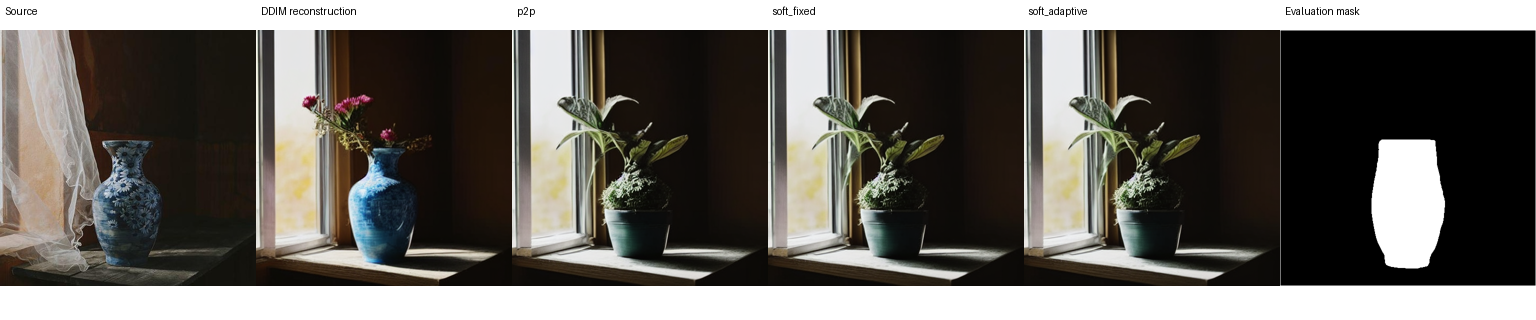

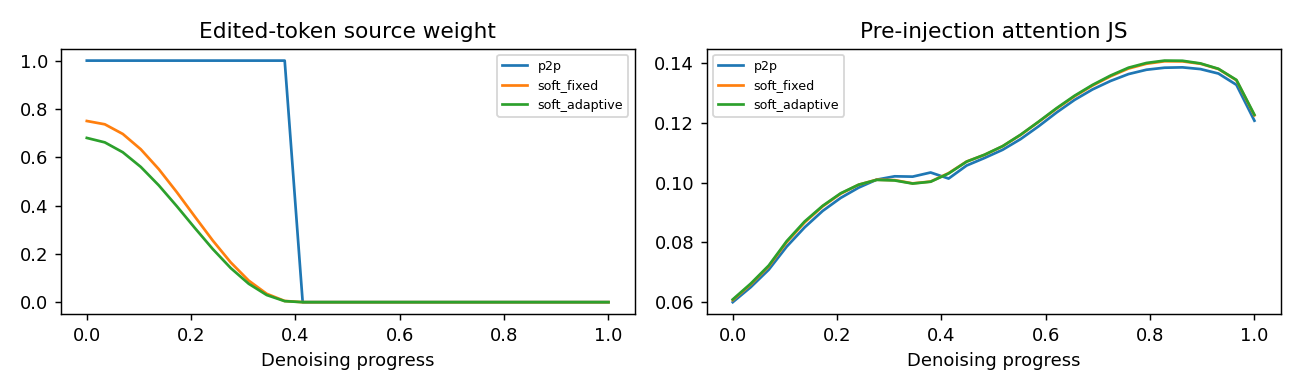

**114000000002 / category 1**

a painting of a castle in the middle of a lake → a painting of a gaint in the middle of a lake

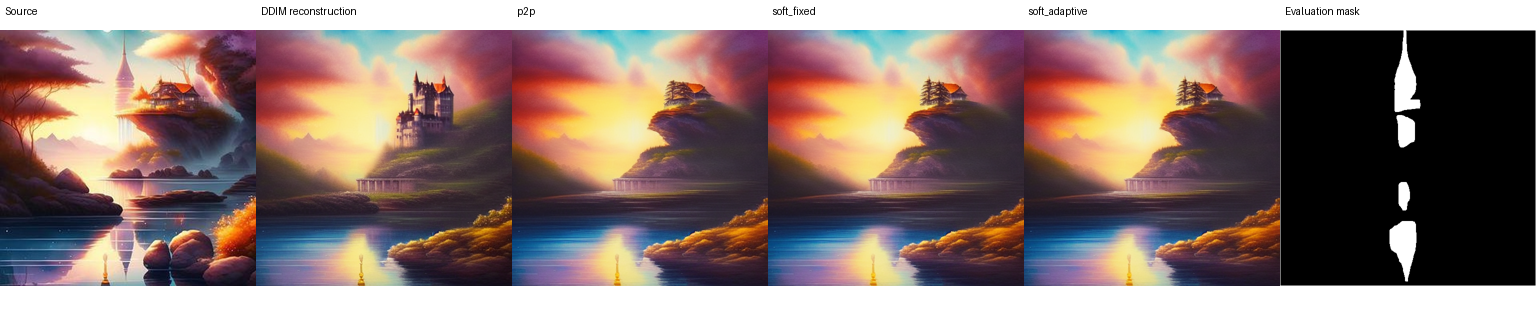

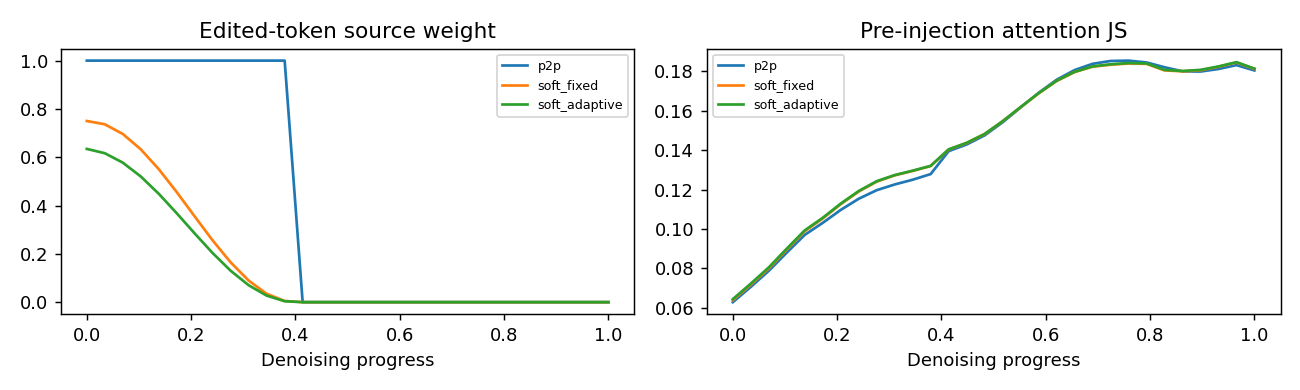

**111000000004 / category 1**

a cartoon painting of a cute owl with a heart on its body → a cartoon painting of a cute owl with a circle on its body

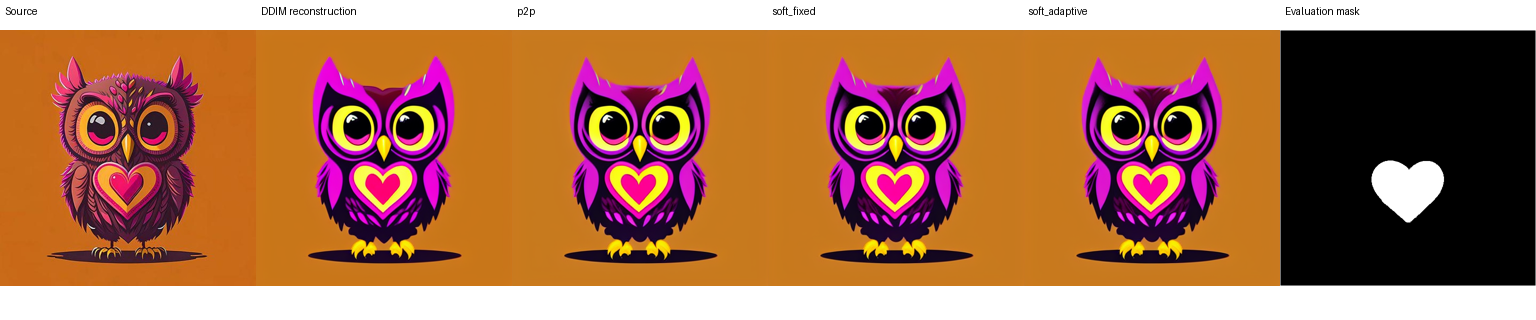

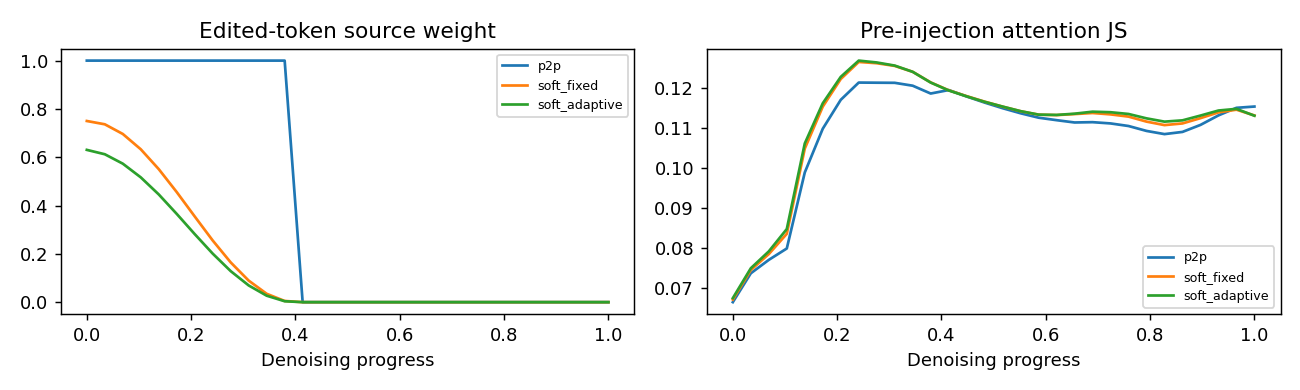

**114000000007 / category 1**

a woman in a dress standing in front of a spaceship → a woman in a dress standing in front of a eagle

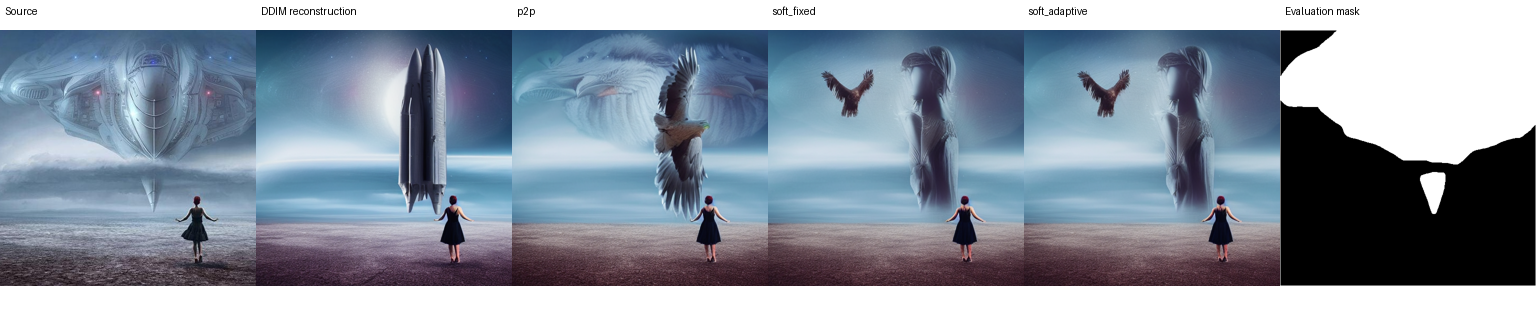

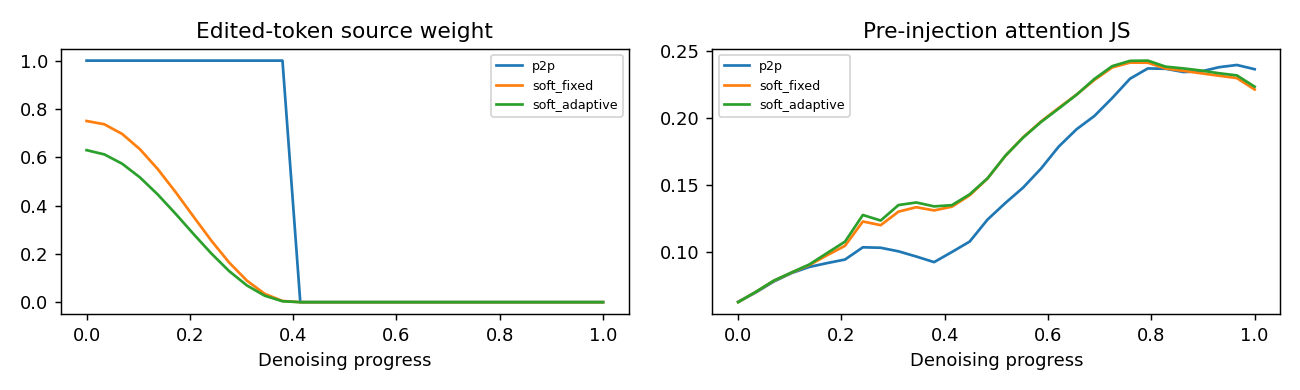

**121000000002 / category 1**

a horse in a grass field → a zebra in a grass field

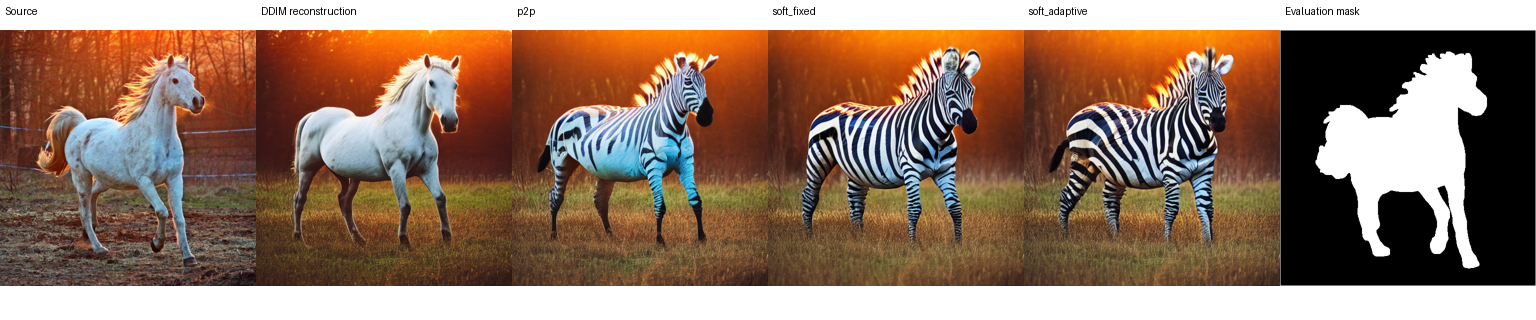

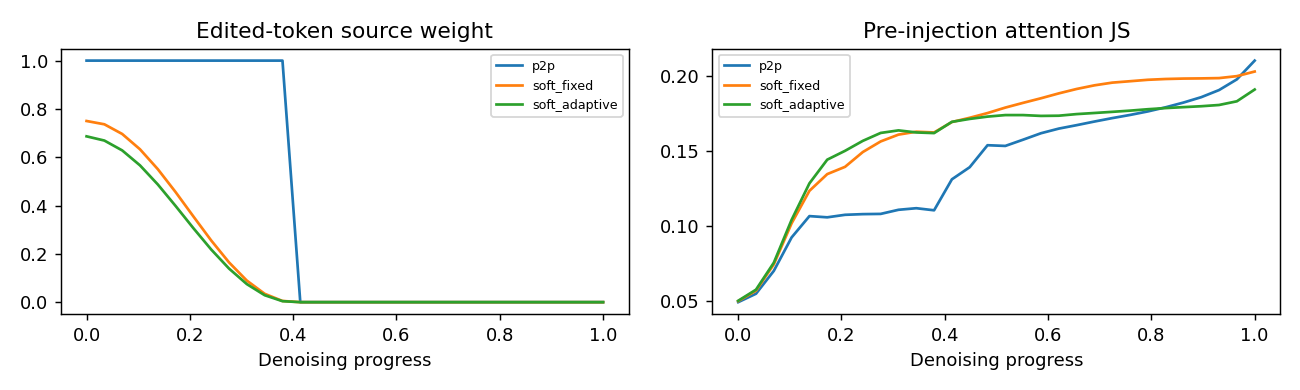

**121000000000 / category 1**

an orange cat play with a black and white cat in the grass → an orange cat play with a big pink yarn ball in the grass

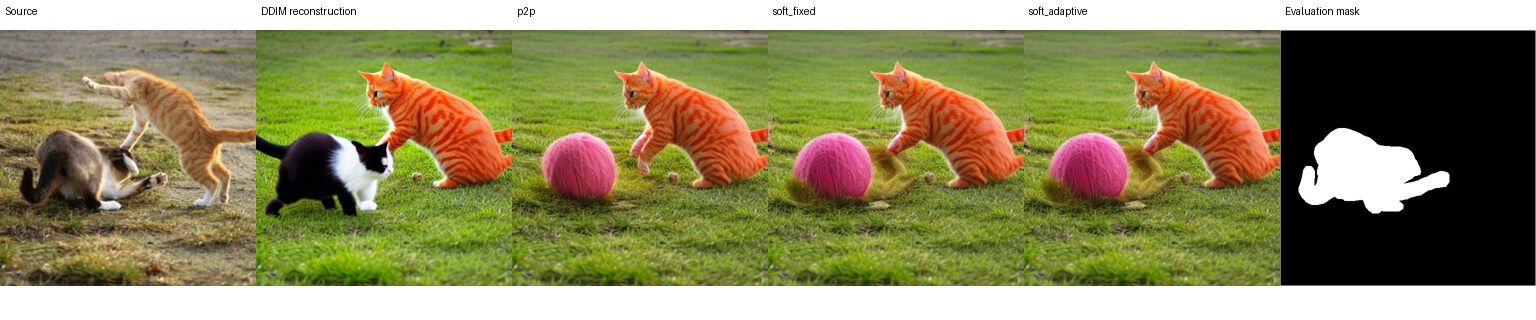

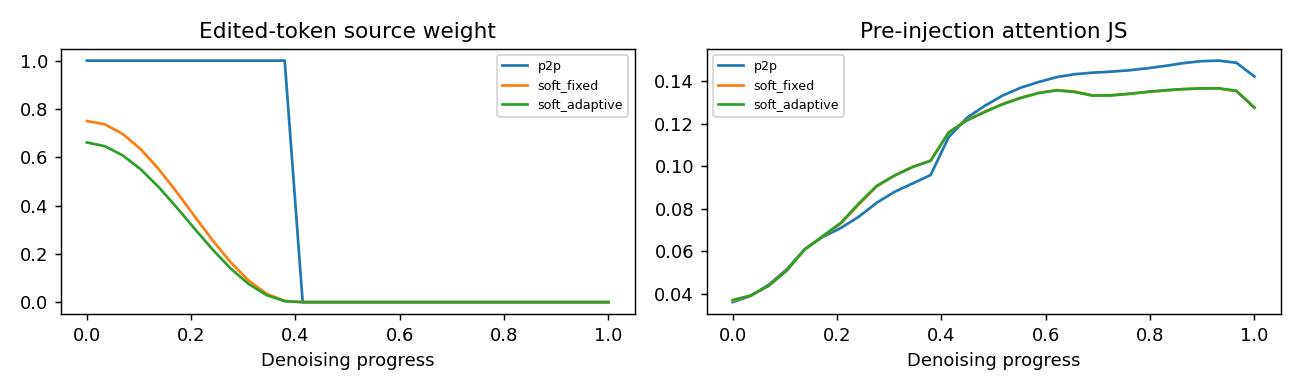

**122000000004 / category 1**

a woman in black dress leaning against a car → a woman in black dress leaning against a wall

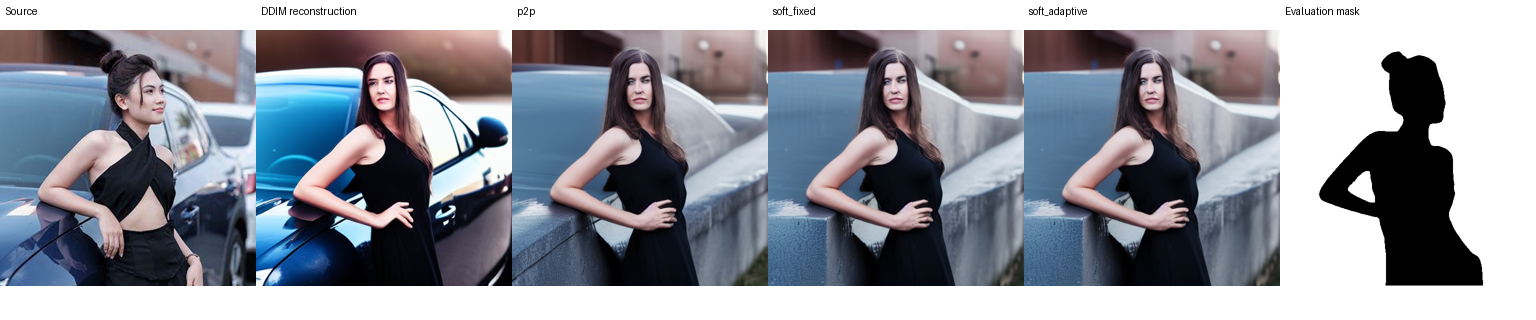

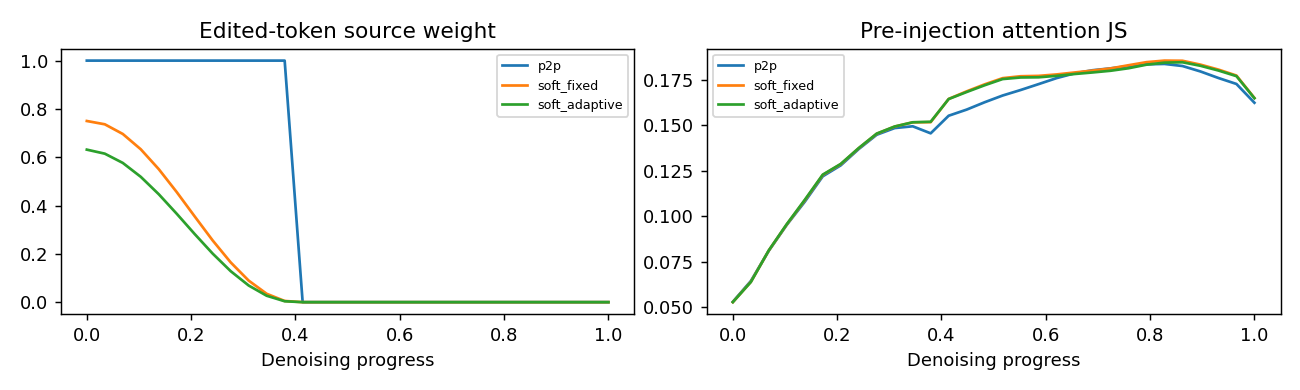

**114000000009 / category 1**

the jungle with a beautiful waterfall → the jungle with a star river

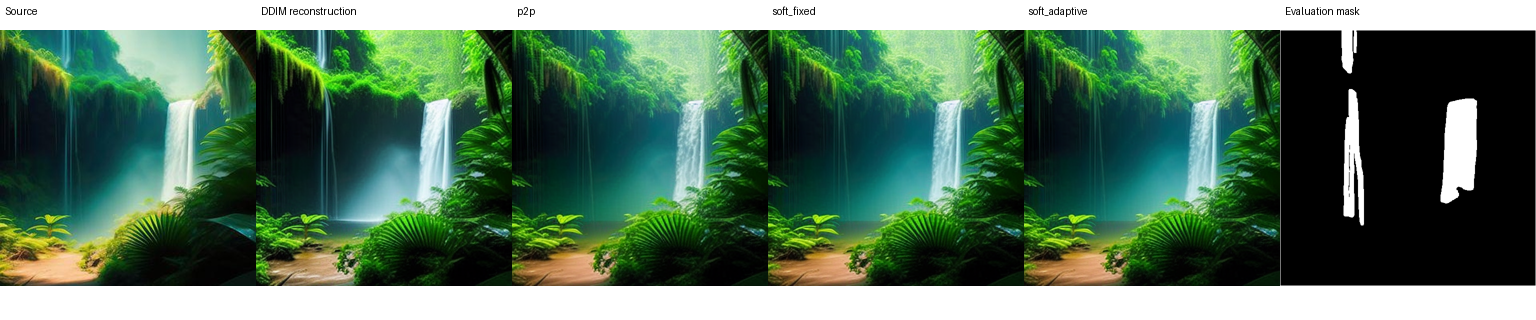

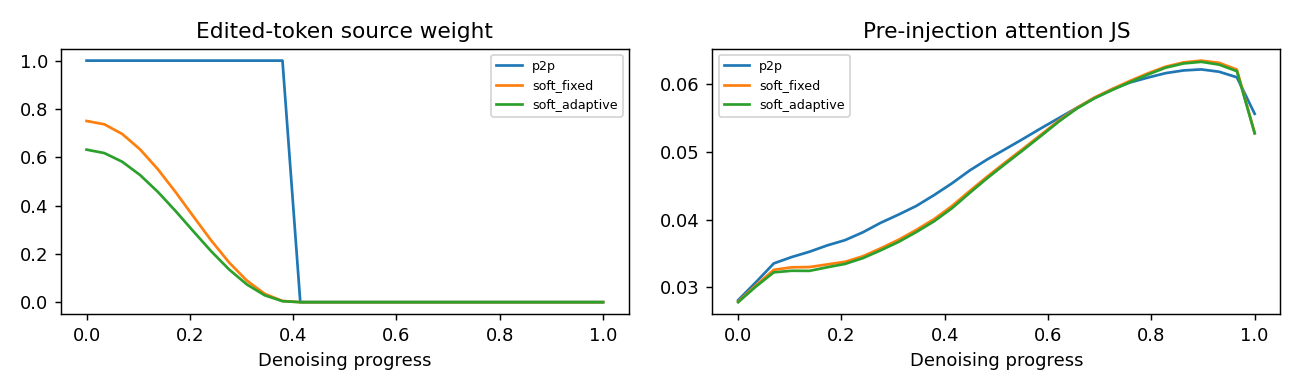

In [10]:
PAGE = 1  # 从1开始
PAGE_SIZE = 8
CATEGORY_FILTER = None  # 例如 "6"
SAMPLE_IDS = None       # 例如 ["613000000002"]
manifest = json.loads((OUTPUT_DIR / "manifest.json").read_text(encoding="utf-8"))
samples = [s for s in manifest["samples"] if s["split"] == "test"
           and (CATEGORY_FILTER is None or s["category"] == str(CATEGORY_FILTER))
           and (SAMPLE_IDS is None or s["id"] in SAMPLE_IDS)
           and (OUTPUT_DIR / "qualitative" / s["id"] / "comparison.png").exists()]
if PAGE < 1 or PAGE_SIZE < 1:
    raise ValueError("PAGE and PAGE_SIZE must be positive.")
print(f"{len(samples)} completed samples; page {PAGE}/{max(1, (len(samples)+PAGE_SIZE-1)//PAGE_SIZE)}")
for sample in samples[(PAGE-1)*PAGE_SIZE:PAGE*PAGE_SIZE]:
    folder = OUTPUT_DIR / "qualitative" / sample["id"]
    prompts = sample["case"]
    display(Markdown(f"**{sample['id']} / category {sample['category']}**\n\n{prompts['source_prompt']} → {prompts['target_prompt']}"))
    display(DisplayImage(filename=str(folder / "comparison.png")))
    display(DisplayImage(filename=str(folder / "weights.png")))

## 9. 运行完整性检查与导出

检查三方法文件与源分支一致性，保存GPU及覆盖信息；运行完整性不等同于方法有效性。
`report`包供分享，`checkpoint`额外包含反演latent，可恢复到原远程路径。
原始数据和模型缓存由Drive单独保存，不放入结果ZIP。

In [11]:
from tqdm.auto import tqdm
import numpy as np
from PIL import Image
from evaluate_adaptive_p2p import valid_result
manifest = json.loads((OUTPUT_DIR / "manifest.json").read_text())
registry = json.loads((OUTPUT_DIR / "registry.json").read_text())["records"]
passed = {"real": []}
for sample in tqdm(manifest["samples"], desc="Validate saved results"):
    if sample["split"] == "dev":
        continue
    runs = [r["result"] for r in registry if r["sample_id"] == sample["id"]]
    if {r["method"] for r in runs} != {"p2p", "soft_fixed", "soft_adaptive"}:
        continue
    assert all(valid_result(r) for r in runs)
    sources = [np.asarray(Image.open(r["source_branch_path"])).astype(int) for r in runs]
    assert all(np.abs(x - sources[0]).max() <= 1 for x in sources)
    passed[sample["kind"]].append(sample["id"])
validation = {"gpu": torch.cuda.get_device_name(0),
              "real_smoke": bool(passed["real"]),
              "complete_sample_ids": passed,
              "coverage": json.loads((OUTPUT_DIR / "coverage.json").read_text(encoding="utf-8")),
              "status": json.loads((OUTPUT_DIR / "status.json").read_text(encoding="utf-8")), "metrics_report_exists": (OUTPUT_DIR / "summary.csv").exists(),
              "note": "Runtime integrity only; see coverage and paired metrics for actual effectiveness."}
save_json(OUTPUT_DIR / "colab_validation.json", validation)
print(validation)
# report用于分享；checkpoint包含初始latent，用于恢复到相同的远端绝对路径。
# 不包含模型缓存或 PIE-Bench 原始数据；更换服务器后需另行准备它们。
import zipfile
for kind in ("report", "checkpoint"):
    export_path = OUTPUT_DIR.parent / (OUTPUT_DIR.name + "_" + kind + ".zip")
    with zipfile.ZipFile(export_path, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in tqdm(list(OUTPUT_DIR.rglob("*")), desc="Export " + kind, unit="file"):
            if path.is_file() and (kind == "checkpoint" or path.suffix != ".pt"):
                archive.write(path, path.relative_to(OUTPUT_DIR.parent))
    print(kind, "remote path:", export_path)
print("从 VS Code 的 Colab Contents 获取上述ZIP，或保留在已挂载Drive。保存notebook本身不会下载结果文件。")

Validate saved results:   0%|          | 0/151 [00:00<?, ?it/s]

{'gpu': 'Tesla T4', 'real_smoke': True, 'complete_sample_ids': {'real': ['113000000002', '114000000002', '111000000004', '114000000007', '121000000002', '121000000000', '122000000004', '114000000009', '112000000002', '112000000008', '123000000002', '124000000005', '123000000006', '113000000000', '111000000000', '111000000007', '111000000001', '111000000005', '124000000000', '111000000002', '124000000003', '124000000004', '122000000008', '114000000001', '123000000007', '113000000007', '124000000009', '112000000000', '113000000004', '112000000009', '121000000006', '123000000008', '113000000005', '114000000006', '123000000001', '112000000007', '113000000003', '122000000005', '112000000001', '113000000009', '114000000005', '122000000002', '121000000009', '114000000004', '111000000008', '112000000005', '111000000009', '124000000001', '121000000007', '121000000001', '113000000008', '121000000004', '123000000003', '114000000000', '113000000001', '122000000007', '111000000006', '121000000003',

Export report:   0%|          | 0/5165 [00:00<?, ?file/s]

report remote path: /content/drive/MyDrive/p2p_research/pie_subset_v2_report.zip


Export checkpoint:   0%|          | 0/5165 [00:00<?, ?file/s]

checkpoint remote path: /content/drive/MyDrive/p2p_research/pie_subset_v2_checkpoint.zip
从 VS Code 的 Colab Contents 获取上述ZIP，或保留在已挂载Drive。保存notebook本身不会下载结果文件。
